# CONVIVE: visitors and residents in the same space
**Team 102_A (Convive Lab) · Mobile Data Challenge 2026 (Cátedra Telefónica UPF-UPC), Challenge #2 · Iteration 1 product increment**

> ⚠️ **SYNTHETIC DATA.** The Telefónica Tech (Smart Steps) files are not available yet. Everything below runs on synthetic files with **exactly the columns of the official data description**, produced by an explicit model (`synthetic.py`). The numbers do not describe Barcelona. Because we know what the model contains, each method is also **validated**: we check that it recovers what was planted. When the real files are placed in `data/raw/`, the same notebook runs on them unchanged.

### What this increment delivers (PWP, SC-04)
| Committed item | Where |
|---|---|
| Notebook structure | This notebook: an end-to-end pipeline from raw files to indicators, maps and an index |
| Base neighbourhood map | §3: 73 neighbourhoods linked to the Smart Steps codes, areas, centroids and spatial weights |
| Data review and cleaning plan | §2: automated schema, content and cross-file consistency checks, with planted problems detected |

### Analytical toolkit built and tested
| § | Question for the challenge | Method |
|---|---|---|
| 4 | When do visitors come, and what is an "unusual" day? | Robust harmonic regression (trend + yearly Fourier cycle + weekday effect), event detection on 76 series validated against 17 planted events, same-weekday year-on-year change |
| 5 | Where do visitors concentrate, and is it changing? | Density per km², location quotients, Gini and Lorenz curves, Moran's I and LISA hot spots, weighted mean centre and standard distance |
| 6 | Which kinds of neighbourhoods exist? | k-means typologies on 7 indicators, silhouette selection, PCA |
| 7 | Do visitors and residents move differently? | Gravity model with fixed effects, corrected for the privacy threshold (censored Poisson MLE), PageRank on the trip network, visitor share of arrivals |
| 8 | Where is coexistence under most pressure? | Composite Coexistence Pressure Index with a weight-sensitivity analysis |
| 9 | Who are the visitors and how long do they stay? | Country seasonality and growth, length-of-stay distribution |
| 10 | Is every requirement covered? | Traceability to the PWP requirements (RQ-01 to RQ-18), limitations, next steps |

## 0. Setup

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors

import convive as cv
import analysis as an

warnings.filterwarnings("ignore", category=FutureWarning)
DATA_MODE = "auto"        # "auto": real files in data/raw/ when present, otherwise synthetic
cv.OUT_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 80, "display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
COLORS = {"Internacional": "#1f6fb4", "Nacional": "#f08a24", "Regional": "#2ca02c", "Residente": "#c0392b"}
VISITORS = ["Internacional", "Nacional", "Regional"]

def save(fig, name):
    fig.savefig(cv.OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data
### 1.1 Catalogue
Twelve files are announced: 3 mobility files (**trips** between areas, per day) and 9 tourism files (**unique visitors** present in an area). This increment works with the 7 that the core questions need (T1, T2, T3, T4, T5, T8, M1). The remaining ones (M2, M3, T6, T7, T9) plug into the same loader.

In [2]:
cv.catalogue()

,id,file,description,n_columns
0,M1,movilidad_barrios,"Trips between Barcelona neighbourhoods, per day",13
1,M2,movilidad_municipios,"Trips between municipalities of the province, per day",9
2,M3,movilidad_barrios_municipios,"Trips between Barcelona neighbourhoods and municipalities, per day",13
3,T1,visitantes_unicos_municipio_yearmon,"Unique visitors in the municipality, per month",7
4,T2,visitantes_unicos_municipio_date_dt,"Unique visitors in the municipality, per day",8
5,T3,pernoctaciones_semana,"Tourists by number of overnight stays, per week (municipality)",9
6,T4,visitantes_unicos_barrio_yearmon,"Unique visitors per neighbourhood, per month",8
7,T5,visitantes_unicos_barrio_date_dt,"Unique visitors per neighbourhood, per day",9
8,T6,visitantes_regionales_barrio_yearmon,"Regional visitors per neighbourhood and municipality of residence, per month",9
9,T7,visitantes_nacionales_barrio_yearmon,"National visitors per neighbourhood and province of residence, per month",8


**Interpretation rules** taken from the data description. The code enforces them:
1. **Trips ≠ visitors.** Mobility counts trips (one person can make several), and tourism counts unique people. They are never mixed in one indicator.
2. **Unique visitors are not additive.** Adding days does not give the month, and adding neighbourhoods does not give the city. City figures come from T1/T2, and §2.3 uses this to test consistency.
3. **`origen` is a segment** (Residente, Regional, Nacional, Internacional), not where the trip starts.
4. **Privacy threshold.** Fewer than 15 trips are published as 0, and tourism segments under 15 people are NA. Neither means "nobody".
5. Regional visitors are always excursionists. Overnight stays exist only at municipality level, and only for international and national visitors.

### 1.2 Load

In [3]:
KEYS = ["T1", "T2", "T3", "T4", "T5", "T8", "M1"]
data, source = {}, {}
for key in KEYS:
    df, src = cv.load(key, DATA_MODE)
    if df is None:
        print("No files found: generating synthetic files", cv.make_synthetic_data())
        df, src = cv.load(key, DATA_MODE)
    for m in ("visitantes", "viajes", "pernoctaciones"):
        if m in df.columns:
            df[m] = df[m].astype(float)          # nullable integers -> float (NA stays NaN)
    data[key], source[key] = df, src

SYNTHETIC = "synthetic" in source.values()
TAG = " · SYNTHETIC DATA" if SYNTHETIC else ""
truth = json.loads((cv.SAMPLE_DIR / "_synthetic_truth.json").read_text()) if SYNTHETIC else None

pd.DataFrame({k: {"file": cv.SCHEMAS[k]["file"], "rows": f"{len(v):,}", "columns": v.shape[1], "source": source[k].upper()}
              for k, v in data.items()}).T

No files found: generating synthetic files {'T1': 160, 'T2': 4855, 'T3': 1946, 'T4': 11680, 'T5': 354415, 'T8': 70080, 'M1': 294376}


,file,rows,columns,source
T1,visitantes_unicos_municipio_yearmon,160,7,SYNTHETIC
T2,visitantes_unicos_municipio_date_dt,"4,855",8,SYNTHETIC
T3,pernoctaciones_semana,"1,946",9,SYNTHETIC
T4,visitantes_unicos_barrio_yearmon,"11,680",8,SYNTHETIC
T5,visitantes_unicos_barrio_date_dt,"354,415",9,SYNTHETIC
T8,visitantes_internacionales_barrio_yearmon,"70,080",8,SYNTHETIC
M1,movilidad_barrios,"294,376",13,SYNTHETIC


## 2. Data review and cleaning (Iteration 1 deliverable)
The plan in `data_review_plan.md` runs here in three layers: **structure** (does each file look like its description?), **content** (duplicates, NA, privacy zeros, categories, coverage) and **cross-file consistency** (do the files agree with each other?). Every problem gets an action, and the action is logged.

### 2.1 Structure and content checks per file

In [4]:
geo, barris = cv.load_barris()
rows = []
for key, df in data.items():
    for check, result, ok in cv.review(df, key, barris):
        rows.append({"file": key, "check": check, "result": result, "status": "OK" if ok else "REVIEW"})
review = pd.DataFrame(rows)
summary = review.groupby("file")["status"].value_counts().unstack(fill_value=0).reindex(KEYS)
display(summary)
print("Checks that need attention:")
review[review["status"] == "REVIEW"]

status,OK,REVIEW
file,,
T1,9,0
T2,9,1
T3,8,0
T4,9,1
T5,10,1
T8,9,1
M1,9,1


Checks that need attention:


,file,check,result,status
18,T2,Days covered,"2023-01-01 to 2025-08-31, 971 days, missing: 2024-11-12, 2024-11-13, 2024-11-14",REVIEW
36,T4,'cod_barrio' codes found on the map,73 of 74 (unknown: ['80190399']),REVIEW
46,T5,Days covered,"2023-01-01 to 2025-08-31, 971 days, missing: 2024-11-12, 2024-11-13, 2024-11-14",REVIEW
57,T8,'cod_barrio' codes found on the map,73 of 74 (unknown: ['80190399']),REVIEW
60,M1,Duplicated rows,40,REVIEW


### 2.2 Coverage calendar

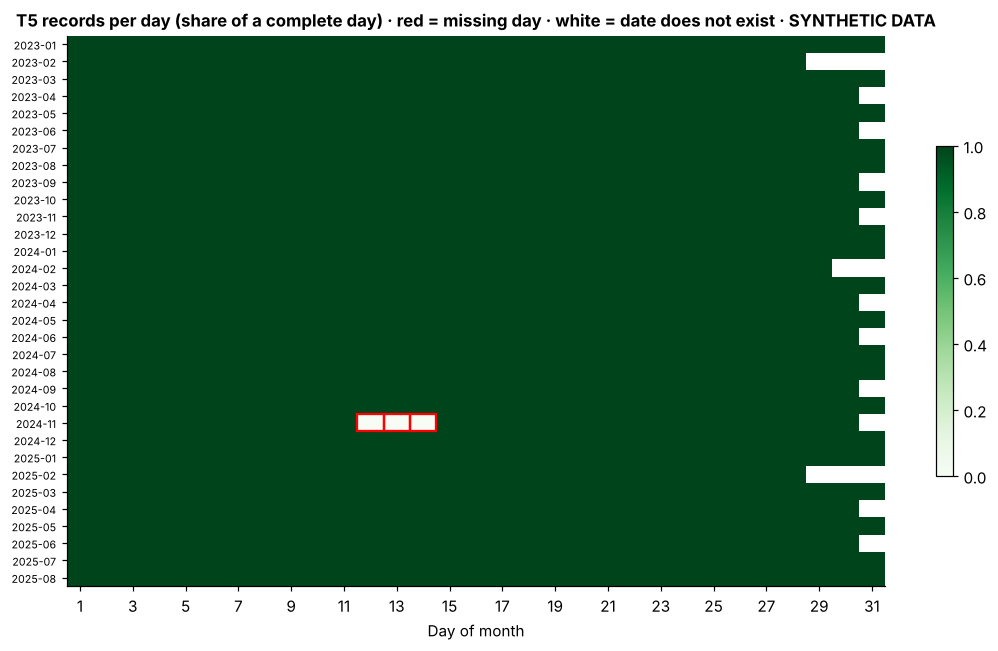

Missing days: ['2024-11-12', '2024-11-13', '2024-11-14']


In [5]:
t5 = data["T5"]
per_day = t5.groupby("date_dt").size()
per_day.index = pd.to_datetime(per_day.index)
full = pd.date_range("2023-01-01", "2025-08-31")
per_day = per_day.reindex(full, fill_value=0)
grid = pd.DataFrame({"month": per_day.index.to_period("M").astype(str), "day": per_day.index.day, "rows": per_day.values})
grid = grid.pivot(index="month", columns="day", values="rows")
expected = grid.stack().max()

fig, ax = plt.subplots(figsize=(12, 6.5))
im = ax.imshow((grid / expected).to_numpy(), aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set_yticks(range(len(grid)), grid.index, fontsize=7); ax.set_xticks(range(0, 31, 2), range(1, 32, 2))
for (r, c) in zip(*np.where(grid.to_numpy() == 0)):
    ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fill=False, ec="red", lw=1.5))
ax.set_title(f"T5 records per day (share of a complete day) · red = missing day · white = date does not exist{TAG}")
ax.set_xlabel("Day of month"); fig.colorbar(im, ax=ax, shrink=.6)
save(fig, "coverage_calendar"); plt.show()
print("Missing days:", [d.strftime("%Y-%m-%d") for d in an.missing_days(t5["date_dt"])])

### 2.3 Cross-file consistency
Unique visitors cannot be added up, but they must respect some **inequalities**. A neighbourhood's daily peak cannot exceed its monthly unique visitors, and no neighbourhood can have more visitors than the whole city. The ratio between the sum of neighbourhoods and the city total also tells us how many neighbourhoods an average visitor passes through each day, which is a useful indicator in its own right.

In [6]:
an.consistency_checks(data['T1'], data['T2'], data['T4'], data['T5'])

,check,result,ok
0,Neighbourhood: max daily unique ≤ monthly unique (T5 vs T4),"0 violations in 11,665 cells",OK
1,Month: largest neighbourhood ≤ whole city (T4 vs T1),0 violations in 160 cells,OK
2,Day: sum of neighbourhoods / city (T5 vs T2) = average neighbourhoods visited,median 1.90 (range 1.90 to 1.90),OK


### 2.4 Cleaning actions (logged)

In [7]:
log = []
m1 = data["M1"]
n = len(m1); m1 = m1.drop_duplicates(); log.append(("M1", "Drop exact duplicate rows", n - len(m1)))

t4 = data["T4"]
unknown = ~t4["cod_barrio"].isin(barris["cod_barrio"])
log.append(("T4", f"Exclude rows with codes not on the map: {sorted(t4.loc[unknown, 'cod_barrio'].unique())}", int(unknown.sum())))
t4 = t4[~unknown]
t8 = data["T8"]; unknown8 = ~t8["cod_barrio"].isin(barris["cod_barrio"])
log.append(("T8", "Exclude rows with codes not on the map (same code)", int(unknown8.sum())))
data["T8"] = t8[~unknown8]

for key in ["T4", "T5", "T8"]:
    log.append((key, "Keep NA (anonymised < 15) as missing, never as 0", int(data[key]["visitantes"].isna().sum())))
log.append(("T2/T5", "Missing days: excluded from daily averages, interpolated only for decomposition", len(an.missing_days(t5["date_dt"]))))

data["M1"], data["T4"] = m1, t4
pd.DataFrame(log, columns=["file", "action", "rows affected"])

,file,action,rows affected
0,M1,Drop exact duplicate rows,40
1,T4,Exclude rows with codes not on the map: ['80190399'],15
2,T8,Exclude rows with codes not on the map (same code),90
3,T4,"Keep NA (anonymised < 15) as missing, never as 0",0
4,T5,"Keep NA (anonymised < 15) as missing, never as 0",0
5,T8,"Keep NA (anonymised < 15) as missing, never as 0",765
6,T2/T5,"Missing days: excluded from daily averages, interpolated only for decomposition",3


In [8]:
if SYNTHETIC:
    planted = pd.DataFrame([
        ("Missing days in T2/T5", ", ".join(truth["missing_days"]), "yes" if set(truth["missing_days"]) <= {d.strftime("%Y-%m-%d") for d in an.missing_days(t5["date_dt"])} else "no"),
        ("Unknown neighbourhood code in T4", truth["unknown_code"], "yes" if (review["result"].str.contains(truth["unknown_code"])).any() else "no"),
        ("Duplicated rows in M1", truth["m1_duplicates"], "yes" if log[0][2] == truth["m1_duplicates"] else "no"),
    ], columns=["planted problem", "value", "detected by the review"])
    display(planted)

,planted problem,value,detected by the review
0,Missing days in T2/T5,"2024-11-12, 2024-11-13, 2024-11-14",yes
1,Unknown neighbourhood code in T4,80190399,yes
2,Duplicated rows in M1,40,yes


## 3. Base neighbourhood map and geography (Iteration 1 deliverable)
Official boundaries of the 73 neighbourhoods (Open Data BCN, CC BY 4.0). The Smart Steps code is `8019` + district + neighbourhood (el Raval = 80190101), which the check in §2.1 confirms against the data. Each neighbourhood also gets its **area** (to turn counts into densities), its **centroid** (for distances and trip lengths) and **spatial weights**, which say which neighbourhoods are neighbours and are needed for the spatial statistics in §5.

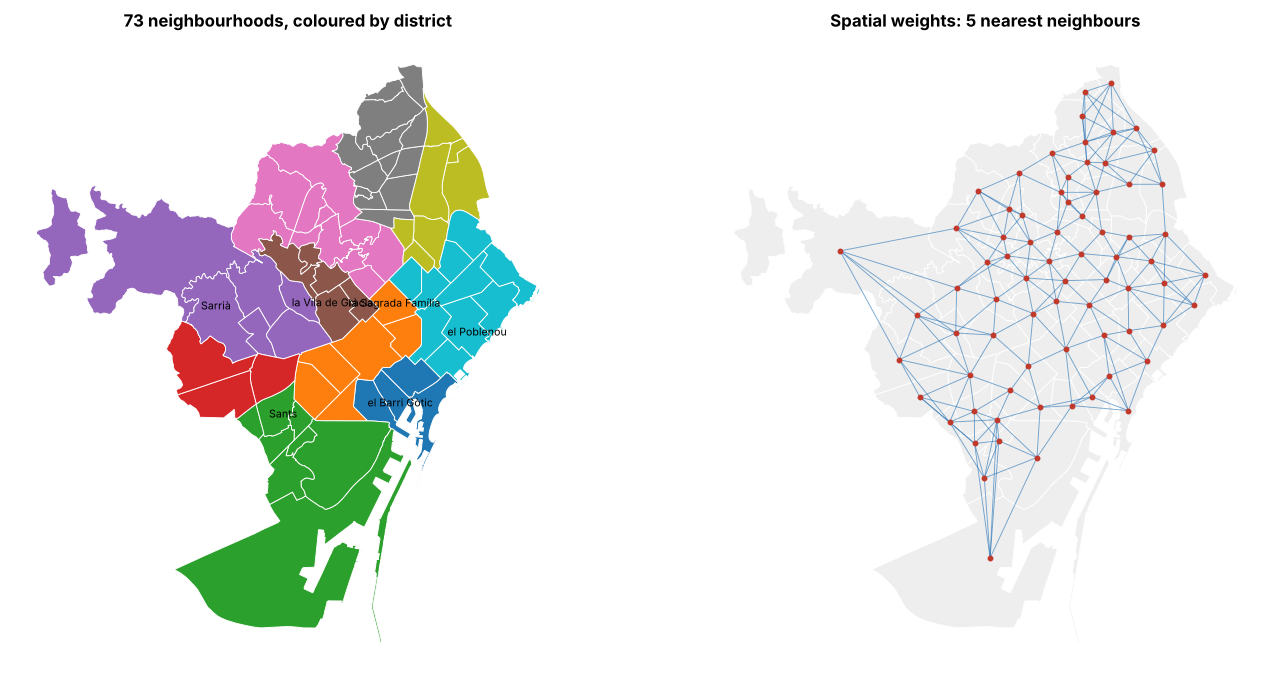

City area 101.6 km² · smallest 0.12 km² · largest 14.2 km² · interactive map: outputs/base_map_interactive.html


In [9]:
geom = an.centroids(geo).merge(barris, on="cod_barrio")
LONLAT = geom[["lon", "lat"]].to_numpy()
W = an.knn_weights(LONLAT, k=5)
CODES = geom["cod_barrio"].to_numpy()
NAME = dict(zip(geom["cod_barrio"], geom["barrio_name"]))
AREA = geom.set_index("cod_barrio")["area_km2"]

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
cv.plot_map(geo, ax=axes[0], title="73 neighbourhoods, coloured by district",
            label=["80190102", "80190206", "80191068", "80190523", "80190318", "80190631"])
cv.plot_map(geo, ax=axes[1], categories={c: "#eeeeee" for c in CODES}, title="Spatial weights: 5 nearest neighbours")
for i, j in zip(*np.where(np.triu(W) > 0)):
    axes[1].plot(LONLAT[[i, j], 0], LONLAT[[i, j], 1], color="#1f6fb4", lw=.6, alpha=.6)
axes[1].scatter(LONLAT[:, 0], LONLAT[:, 1], s=8, color="#c0392b", zorder=3)
save(fig, "base_map"); plt.show()
cv.interactive_map(geo, barris, path=cv.OUT_DIR / "base_map_interactive.html")
print(f"City area {AREA.sum():.1f} km² · smallest {AREA.min():.2f} km² · largest {AREA.max():.1f} km² · interactive map: outputs/base_map_interactive.html")

## 4. When: temporal patterns (RQ-01, RQ-10)
### 4.1 Monthly evolution by origin (T1)

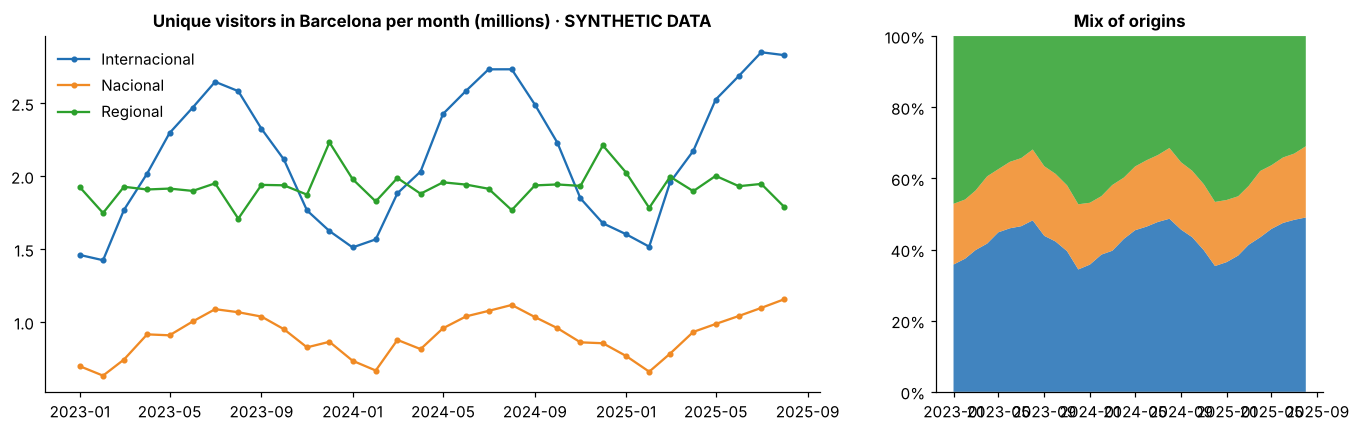

In [10]:
t1 = data["T1"].copy()
t1["date"] = pd.to_datetime(t1["mes"], format="%Y%m")
monthly = t1.groupby(["date", "origen"])["visitantes"].sum().unstack()[VISITORS]   # tourists + excursionists are different people

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2, 1]})
for o in VISITORS:
    axes[0].plot(monthly.index, monthly[o] / 1e6, marker=".", color=COLORS[o], label=o)
axes[0].set_title(f"Unique visitors in Barcelona per month (millions){TAG}"); axes[0].legend(frameon=False)
share = monthly.div(monthly.sum(axis=1), axis=0)
axes[1].stackplot(share.index, share.T, colors=[COLORS[o] for o in VISITORS], alpha=.85, labels=VISITORS)
axes[1].set_title("Mix of origins"); axes[1].set_ylim(0, 1); axes[1].yaxis.set_major_formatter("{x:.0%}")
save(fig, "monthly_visitors"); plt.show()

### 4.2 Decomposition of the daily series (robust harmonic regression)
Each daily series (T2) is modelled on a log scale as **trend** (quadratic) + **yearly cycle** (6 Fourier harmonics) + **weekday effect** + **residual**. Taking logs makes the components multiplicative, so a weekday effect of +0.10 means about 10% above an average day.
- *Why not classical STL/MSTL?* With only 32 months (fewer than 3 yearly cycles), STL's yearly component overfits each year and swallows the events. A smooth Fourier curve cannot follow a 4-day spike, so events remain in the residual.
- *Robustness:* the model is fitted twice. Days that are extreme in the first fit get zero weight in the second, so events do not distort the seasonal curve.

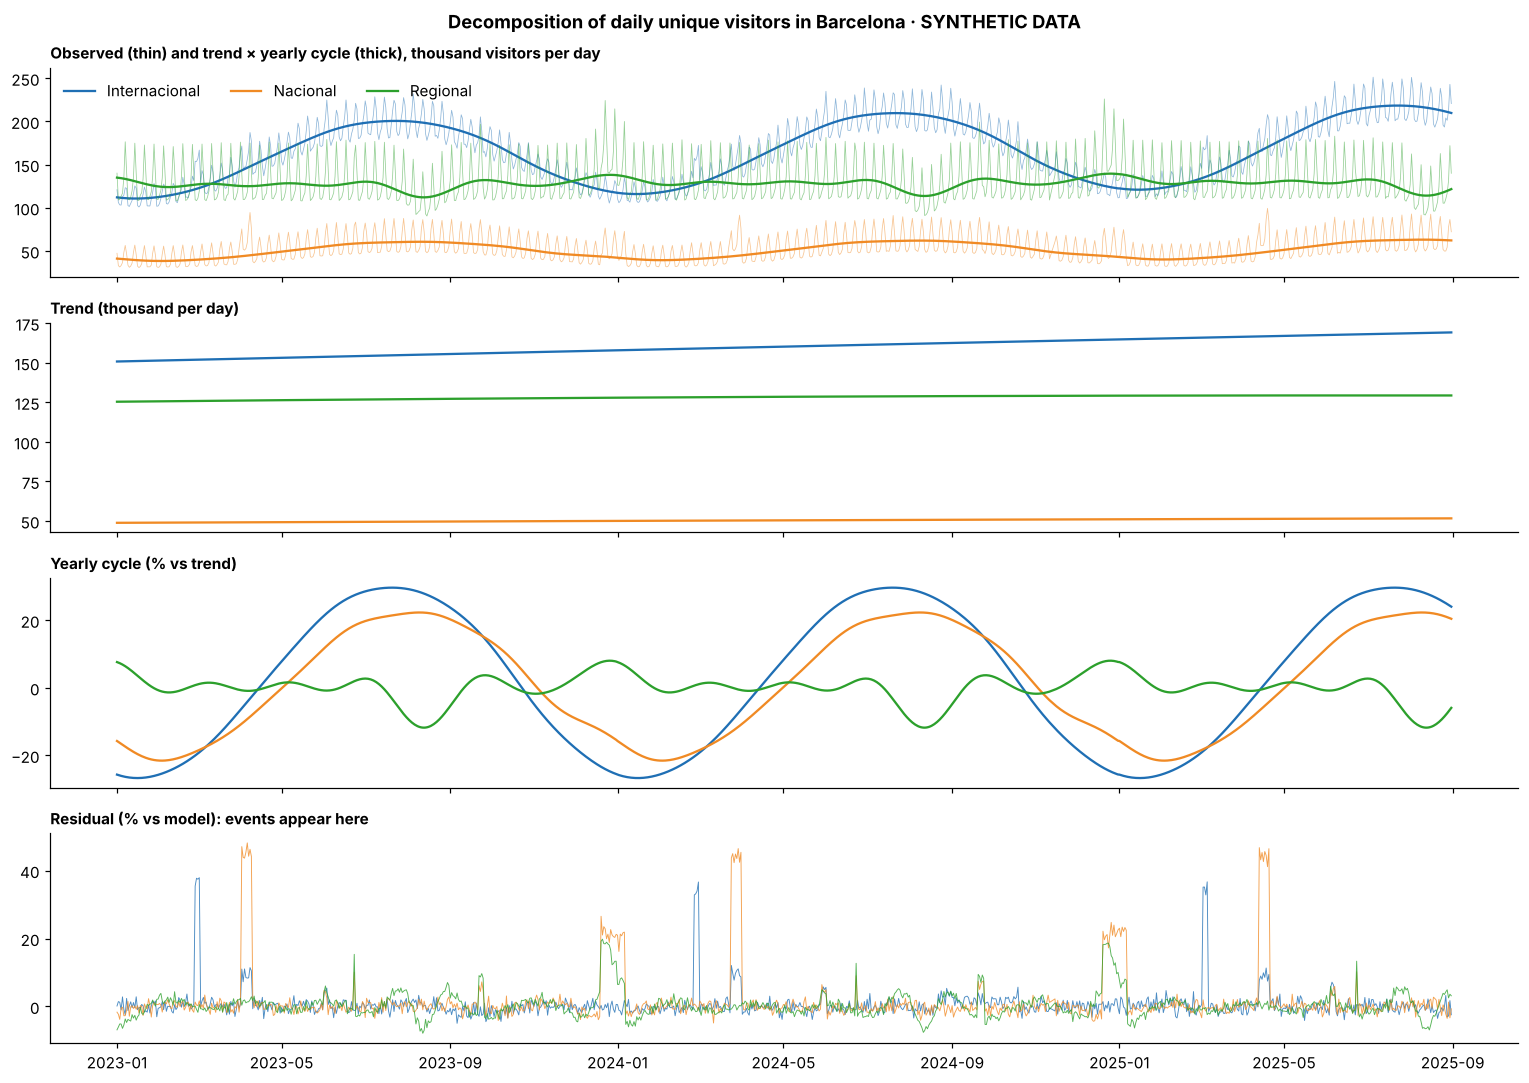

,Internacional,Nacional,Regional
Lunes,-6%,-18%,-14%
Martes,-9%,-20%,-14%
Miércoles,-7%,-18%,-11%
Jueves,-2%,-10%,-7%
Viernes,+4%,+23%,+6%
Sábado,+14%,+44%,+37%
Domingo,+8%,+17%,+12%


In [11]:
t2 = data["T2"].copy()
t2["date"] = pd.to_datetime(t2["date_dt"])
daily = t2.groupby(["date", "origen"])["visitantes"].sum().unstack()[VISITORS]
dec = {o: an.decompose(daily[o]) for o in VISITORS}

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for o in VISITORS:
    d = dec[o]
    axes[0].plot(daily[o] / 1e3, color=COLORS[o], lw=.5, alpha=.5)
    axes[0].plot(np.exp(d["trend"] + d["yearly"]) / 1e3, color=COLORS[o], lw=1.5, label=o)
    axes[1].plot(np.exp(d["trend"]) / 1e3, color=COLORS[o])
    axes[2].plot(np.expm1(d["yearly"]) * 100, color=COLORS[o])
    axes[3].plot(np.expm1(d["resid"]) * 100, color=COLORS[o], lw=.6, alpha=.8)
for ax, t in zip(axes, ["Observed (thin) and trend × yearly cycle (thick), thousand visitors per day", "Trend (thousand per day)",
                        "Yearly cycle (% vs trend)", "Residual (% vs model): events appear here"]):
    ax.set_title(t, loc="left", fontsize=10)
axes[0].legend(frameon=False, ncol=3); fig.suptitle(f"Decomposition of daily unique visitors in Barcelona{TAG}", fontweight="bold")
fig.tight_layout(); save(fig, "decomposition"); plt.show()

weekly_effect = pd.DataFrame({o: dec[o]["weekly"].groupby(dec[o].index.dayofweek).mean() for o in VISITORS})
weekly_effect.index = cv.WEEKDAYS
(np.exp(weekly_effect) - 1).style.format("{:+.0%}").background_gradient(cmap="RdBu_r", vmin=-.3, vmax=.3).set_caption("Weekly effect: % vs an average day")

### 4.3 Event detection
A day is flagged when its residual is **statistically extreme**, by a robust z-score built on the median and MAD so that the outliers we are looking for do not distort the yardstick, and also **practically relevant** (more than 10% above or below the model). Nearby flagged days are grouped into episodes. The scan runs on the 3 city series and on **each of the 73 neighbourhoods** (T5), because a festival can be invisible at city level and obvious in one neighbourhood. For neighbourhoods the bar is stricter (|z| > 4 and more than 15%), since there are 73 series and we want few false alarms.

In [12]:
episodes = []
for o in VISITORS:
    e = an.detect_events(dec[o]["resid"]); e["where"] = "Barcelona"; e["series"] = o; episodes.append(e)

t5d = t5.copy(); t5d["date"] = pd.to_datetime(t5d["date_dt"])
per_barri = t5d.groupby(["date", "cod_barrio"])["visitantes"].sum().unstack()
for code in per_barri.columns:
    e = an.detect_events(an.decompose(per_barri[code])["resid"], threshold=4.0, min_effect=0.15)
    e["where"] = NAME.get(code, code); e["series"] = "all visitors"; episodes.append(e)
episodes = pd.concat(episodes, ignore_index=True).sort_values("peak_z", ascending=False)
print(f"{len(episodes)} episodes found in {len(VISITORS) + per_barri.shape[1]} series. Strongest 15:")
episodes.head(15).reset_index(drop=True)

137 episodes found in 76 series. Strongest 15:


,start,end,days,peak_z,effect,where,series
0,2024-05-29,2024-06-01,4,26.0,+196%,Diagonal Mar i el Front Marítim del Poblenou,all visitors
1,2025-06-04,2025-06-07,4,25.3,+191%,Diagonal Mar i el Front Marítim del Poblenou,all visitors
2,2023-04-02,2023-04-09,8,24.6,+45%,Barcelona,Nacional
3,2025-04-13,2025-04-20,8,24.0,+44%,Barcelona,Nacional
4,2024-03-24,2024-03-31,8,23.9,+44%,Barcelona,Nacional
5,2023-06-01,2023-06-03,3,23.8,+175%,Diagonal Mar i el Front Marítim del Poblenou,all visitors
6,2023-02-27,2023-03-02,4,19.8,+37%,Barcelona,Internacional
7,2024-02-26,2024-02-29,4,19.3,+34%,Barcelona,Internacional
8,2025-03-03,2025-03-06,4,19.3,+35%,Barcelona,Internacional
9,2023-12-20,2024-01-06,18,14.7,+21%,Barcelona,Nacional


In [13]:
if SYNTHETIC:
    events = [(n, s, e) for n, s, e in truth["events"]]
    table, precision, recall = an.match_events(episodes.drop_duplicates(["start", "end"]), events)
    print(f"Validation against the {len(events)} planted events: recall {recall:.0%} (events found) · precision {precision:.0%} (episodes that are real events)")
    def where_found(dates, tol=pd.Timedelta(days=2)):
        start, end = (pd.Timestamp(x) for x in dates.split(" to "))
        hit = episodes[(pd.to_datetime(episodes["start"]) <= end + tol) & (pd.to_datetime(episodes["end"]) >= start - tol)]
        places = list(dict.fromkeys(hit.sort_values("peak_z", ascending=False)["where"]))
        return ", ".join(places[:3]) + (f" (+{len(places) - 3})" if len(places) > 3 else "")
    table["where detected"] = table["dates"].map(where_found)
    display(table.drop(columns="detected as"))

Validation against the 17 planted events: recall 100% (events found) · precision 91% (episodes that are real events)


,event,dates,detected,where detected
0,Mobile World Congress 2023,2023-02-27 to 2023-03-02,yes,"Barcelona, el Barri Gòtic, la Sagrada Família (+8)"
1,Mobile World Congress 2024,2024-02-26 to 2024-02-29,yes,"Barcelona, l'Antiga Esquerra de l'Eixample, el Barri Gòtic (+13)"
2,Mobile World Congress 2025,2025-03-03 to 2025-03-06,yes,"Barcelona, l'Antiga Esquerra de l'Eixample, la Sagrada Família (+7)"
3,Easter 2023,2023-04-02 to 2023-04-09,yes,"Barcelona, l'Antiga Esquerra de l'Eixample, la Vila Olímpica del Poblenou (+5)"
4,Easter 2024,2024-03-24 to 2024-03-31,yes,"Barcelona, Sant Antoni, el Fort Pienc (+3)"
5,Easter 2025,2025-04-13 to 2025-04-20,yes,"Barcelona, la Sagrada Família, el Poblenou (+5)"
6,Primavera Sound 2023,2023-06-01 to 2023-06-03,yes,Diagonal Mar i el Front Marítim del Poblenou
7,Primavera Sound 2024,2024-05-29 to 2024-06-01,yes,Diagonal Mar i el Front Marítim del Poblenou
8,Primavera Sound 2025,2025-06-04 to 2025-06-07,yes,Diagonal Mar i el Front Marítim del Poblenou
9,Sant Joan 2023,2023-06-23 to 2023-06-23,yes,"Diagonal Mar i el Front Marítim del Poblenou, la Vila Olímpica del Poblenou,..."


**How to read the validation.** The detector finds the planted events, and in the right place: city-wide ones (congress, Easter, Christmas) in the city series, and local ones (festival, Sant Joan, La Mercè) in their neighbourhoods. The few remaining "false alarms" are mostly the edges of long events or their spill-over into neighbouring areas. With real data the same scan becomes a **discovery tool**: every episode it reports is either an event we can name (and add to a calendar of known events) or a data problem to ask the mentor about.

### 4.4 Equivalent periods: year-on-year change
Comparing a month with the same month of the previous year is distorted by how many weekends each month has. We therefore compare **each day with the same weekday 52 weeks earlier** (364 days) and aggregate by month.

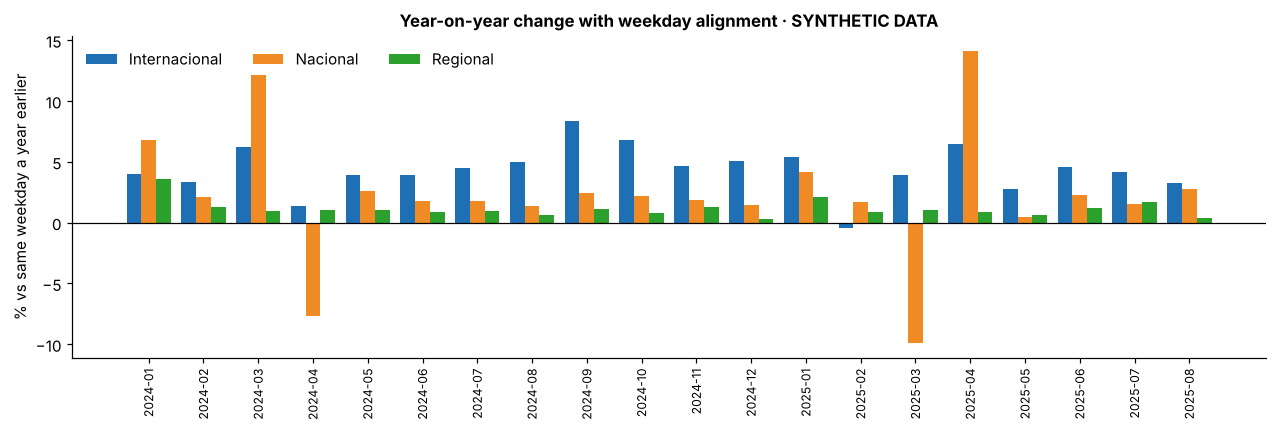

In [14]:
yoy = pd.DataFrame({o: an.yoy_same_weekday(daily[o]) for o in VISITORS})
fig, ax = plt.subplots(figsize=(14, 3.8))
x = np.arange(len(yoy)); w = .27
for i, o in enumerate(VISITORS):
    ax.bar(x + (i - 1) * w, yoy[o] * 100, w, color=COLORS[o], label=o)
ax.axhline(0, color="black", lw=.8); ax.set_xticks(x, yoy.index.astype(str), rotation=90, fontsize=8)
ax.set_ylabel("% vs same weekday a year earlier"); ax.legend(frameon=False, ncol=3)
ax.set_title(f"Year-on-year change with weekday alignment{TAG}")
save(fig, "yoy_same_weekday"); plt.show()

## 5. Where: spatial distribution (RQ-02, RQ-04, RQ-09)
### 5.1 Visitor density
Raw counts favour large neighbourhoods, so we use **unique visitors per km²**: the mean monthly value for September 2024 to August 2025, the last complete year. The scale is logarithmic because densities differ by orders of magnitude.

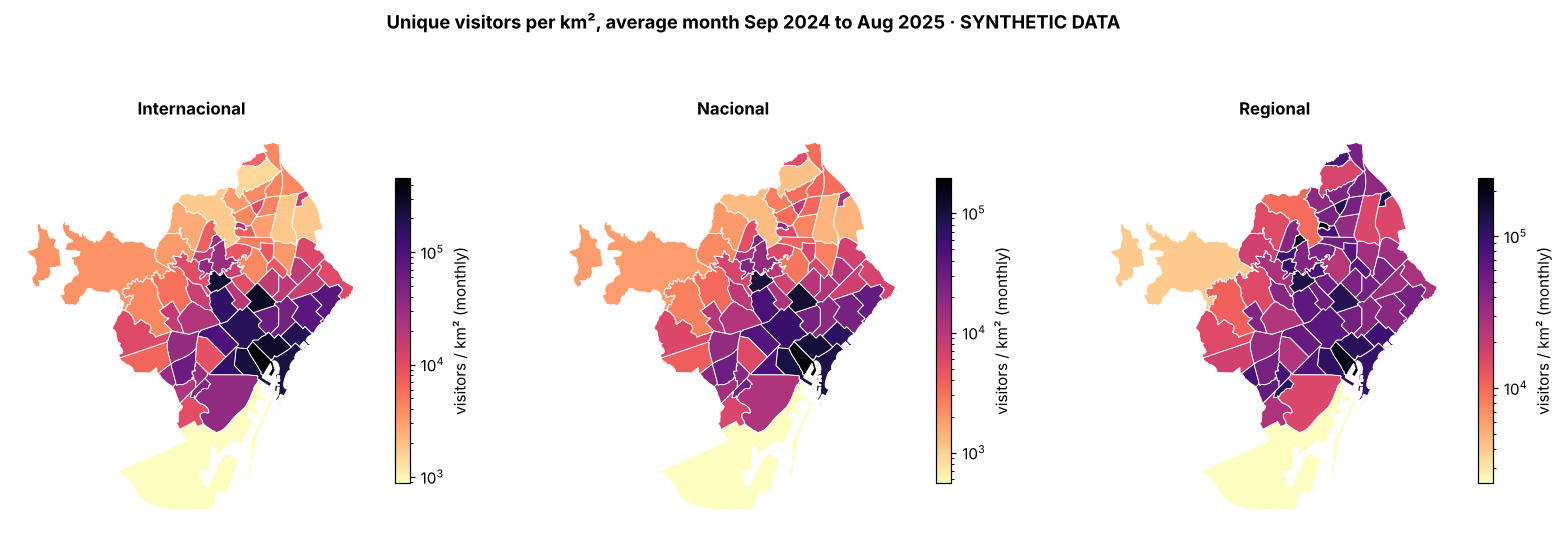

In [15]:
t4 = data["T4"]
last_year = t4[(t4["mes"] >= "202409") & (t4["mes"] <= "202508")]
mean_month = last_year.groupby(["cod_barrio", "origen", "mes"])["visitantes"].sum().groupby(["cod_barrio", "origen"]).mean().unstack()[VISITORS]
density = mean_month.div(AREA, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, o in zip(axes, VISITORS):
    cv.plot_map(geo, values=density[o].to_dict(), ax=ax, log=True, cmap="magma_r", legend_label="visitors / km² (monthly)",
                title=f"{o}")
fig.suptitle(f"Unique visitors per km², average month Sep 2024 to Aug 2025{TAG}", fontweight="bold")
save(fig, "density_maps"); plt.show()

### 5.2 Location quotients: who is over-represented where?
LQ = (share of an origin among a neighbourhood's visitors) / (share of that origin in the city). **LQ > 1** means the origin is over-represented there. This separates "international" neighbourhoods from "local-visitor" ones regardless of their size.

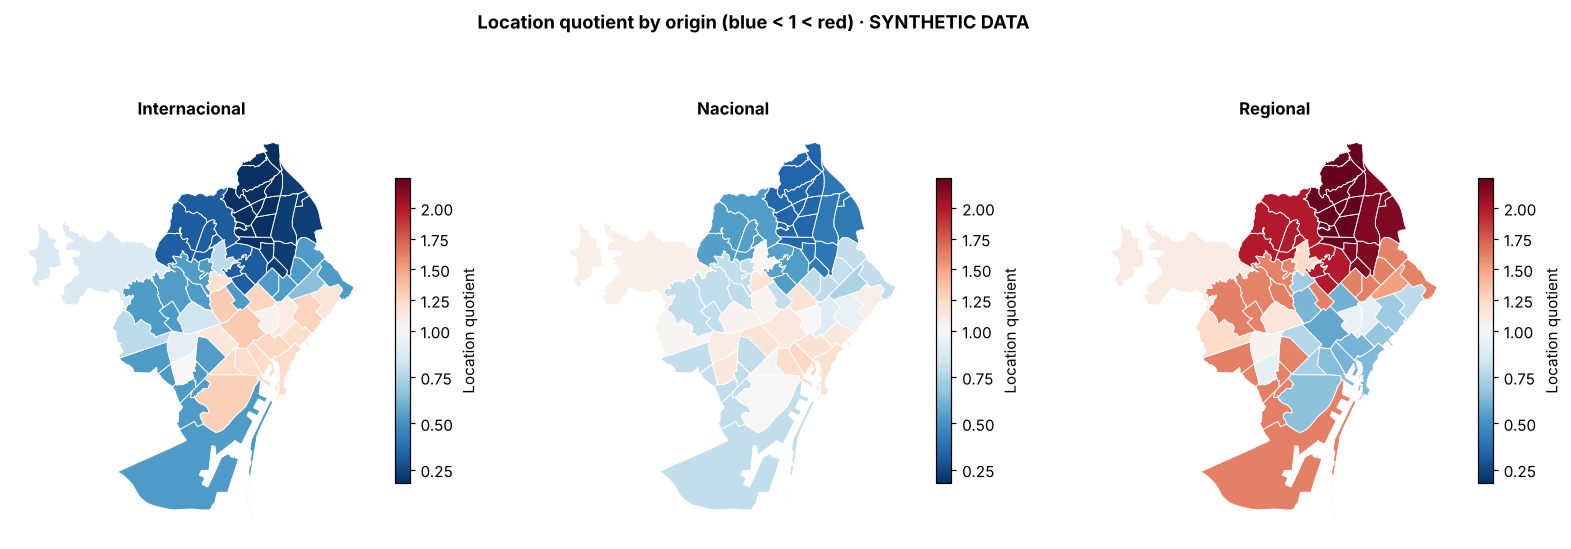

origen,Internacional,Nacional,Regional
cod_barrio,,,
la Dreta de l'Eixample,1.32,1.13,0.57
la Vila de Gràcia,1.32,1.03,0.62
el Poble-sec,1.30,1.01,0.66
el Poblenou,1.29,0.95,0.70
la Sagrada Família,1.28,1.17,0.60
"Sant Pere, Santa Caterina i la Ribera",1.26,1.19,0.62
Sant Antoni,1.25,0.99,0.72
la Barceloneta,1.24,1.20,0.64


In [16]:
LQ = an.location_quotient(mean_month)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, o in zip(axes, VISITORS):
    cv.plot_map(geo, values=LQ[o].to_dict(), ax=ax, cmap="RdBu_r", legend_label="Location quotient",
                norm=colors.TwoSlopeNorm(vcenter=1, vmin=LQ.to_numpy().min(), vmax=LQ.to_numpy().max()), title=o)
fig.suptitle(f"Location quotient by origin (blue < 1 < red){TAG}", fontweight="bold")
save(fig, "location_quotients"); plt.show()
LQ.rename(index=NAME).sort_values("Internacional", ascending=False).head(8).style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=0, vmax=2)

### 5.3 Concentration: Lorenz curves and Gini index
How unequally are visitors spread across the 73 neighbourhoods? A Gini of 0 means every neighbourhood gets the same share, and a Gini of 1 means a single neighbourhood gets them all. Tracking it month by month tells us whether **concentration is increasing**.

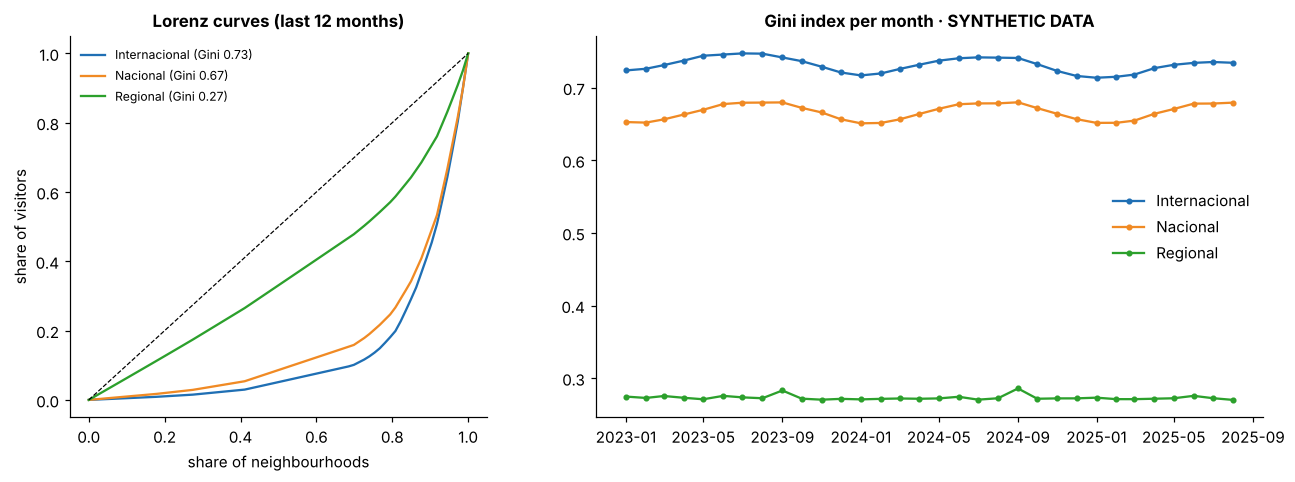

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
for o in VISITORS:
    x, y = an.lorenz(mean_month[o].fillna(0))
    axes[0].plot(x, y, color=COLORS[o], label=f"{o} (Gini {an.gini(mean_month[o].fillna(0)):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=.8); axes[0].set_xlabel("share of neighbourhoods"); axes[0].set_ylabel("share of visitors")
axes[0].legend(frameon=False, fontsize=8); axes[0].set_title("Lorenz curves (last 12 months)")
g = t4.groupby(["mes", "origen", "cod_barrio"])["visitantes"].sum().groupby(["mes", "origen"]).apply(an.gini).unstack()[VISITORS]
g.index = pd.to_datetime(g.index, format="%Y%m")
for o in VISITORS:
    axes[1].plot(g.index, g[o], color=COLORS[o], marker=".", label=o)
axes[1].set_title(f"Gini index per month{TAG}"); axes[1].legend(frameon=False)
save(fig, "concentration"); plt.show()

### 5.4 Spatial autocorrelation: Moran's I and LISA hot spots
Are high-density neighbourhoods next to each other, forming a continuous "visitor zone", or scattered? The **global Moran's I** (with the 5-nearest-neighbour weights from §3) measures this, and its significance comes from 999 random permutations. **LISA** (local Moran) then classifies each neighbourhood as a significant hot spot (high, surrounded by high), cold spot, or outlier.

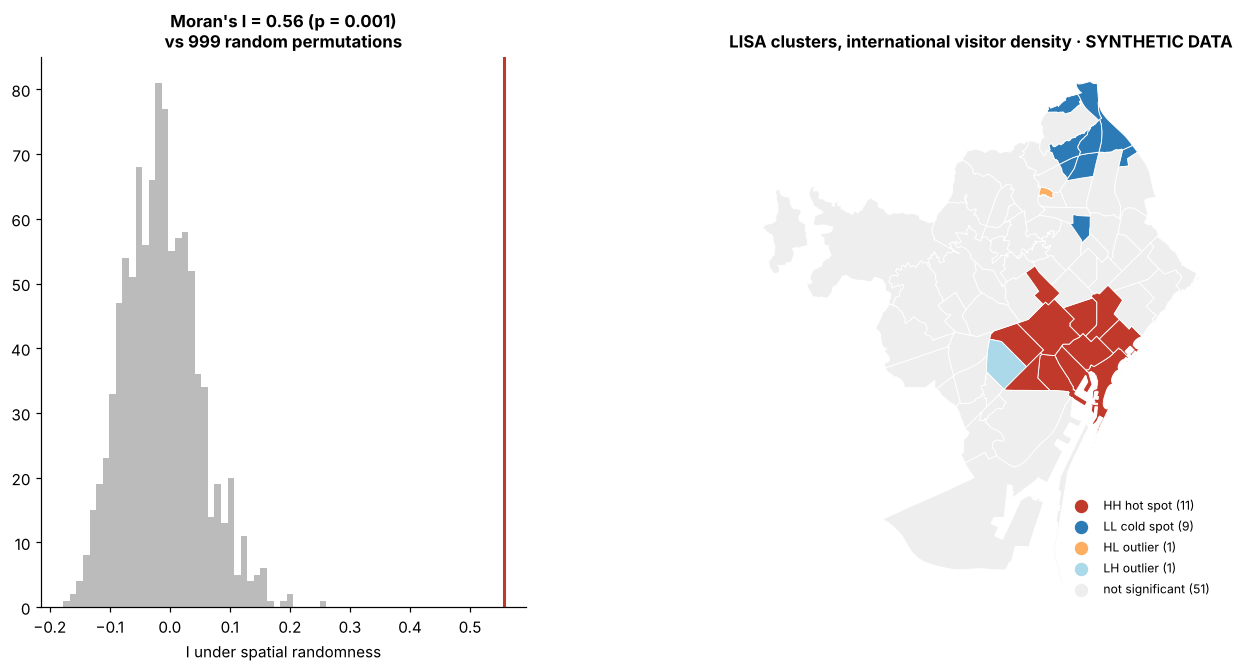

In [18]:
x = np.log(density["Internacional"].reindex(CODES).to_numpy())
I, p, sims = an.morans_i(x, W)
lisa = an.local_moran(x, W); lisa.index = CODES
palette = {"HH hot spot": "#c0392b", "LL cold spot": "#2c7bb6", "HL outlier": "#fdae61", "LH outlier": "#abd9e9", "not significant": "#eeeeee"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].hist(sims, bins=40, color="#bbbbbb"); axes[0].axvline(I, color="#c0392b", lw=2)
axes[0].set_title(f"Moran's I = {I:.2f} (p = {p:.3f})\nvs 999 random permutations"); axes[0].set_xlabel("I under spatial randomness")
cv.plot_map(geo, ax=axes[1], categories={c: palette[t] for c, t in lisa["type"].items()},
            title=f"LISA clusters, international visitor density{TAG}")
for t, c in palette.items():
    axes[1].scatter([], [], color=c, label=f"{t} ({(lisa['type'] == t).sum()})", s=60)
axes[1].legend(frameon=False, loc="lower right", fontsize=8)
save(fig, "morans_lisa"); plt.show()

### 5.5 Is the visitor zone spreading out?
Two complementary measures, for international visitors:
- **Weighted mean centre and standard distance**: the "centre of gravity" of visitors and how far they typically are from it. A rising standard distance means visitors are spreading out.
- **Growth map**: change between January–August 2023 and January–August 2025 (equivalent periods), per neighbourhood.

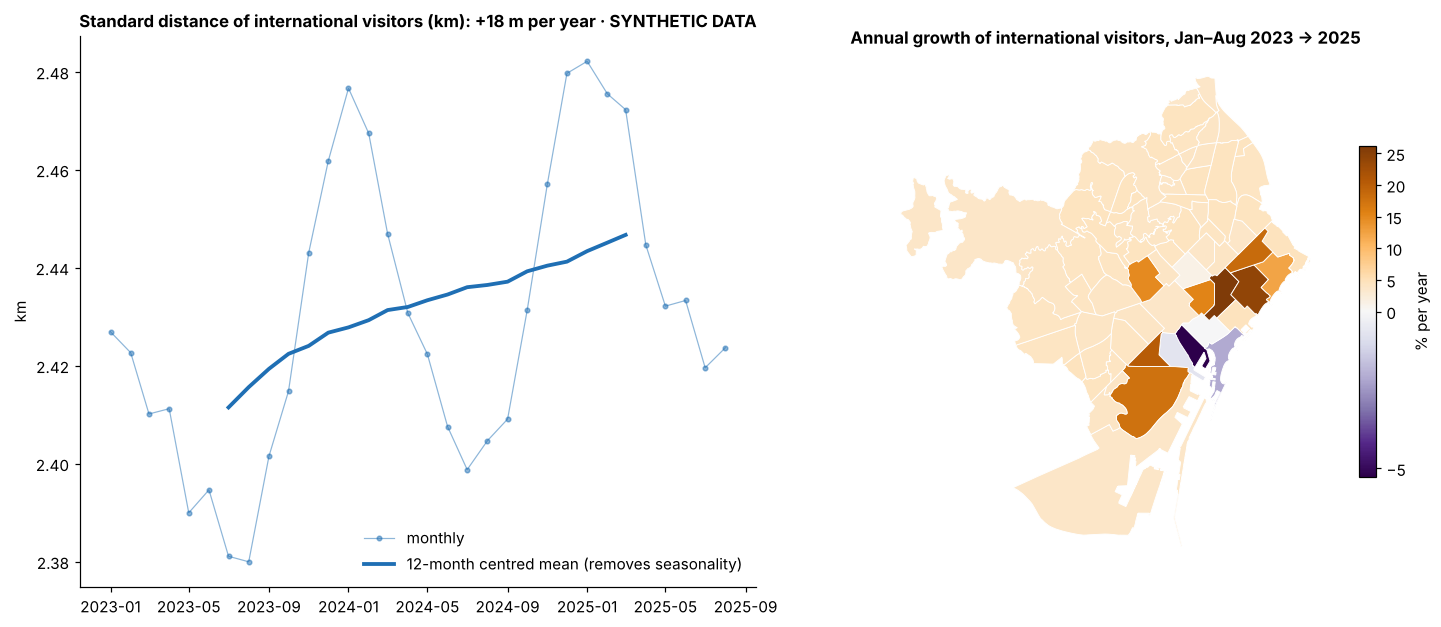

,annual growth
cod_barrio,
el Parc i la Llacuna del Poblenou,+26.1%
el Poblenou,+24.2%
Sant Antoni,+20.3%
Provençals del Poblenou,+18.4%
el Poble-sec,+17.7%
el Fort Pienc,+15.4%
la Vila de Gràcia,+14.8%
Diagonal Mar i el Front Marítim del Poblenou,+12.4%


In [19]:
intl = t4[t4["origen"] == "Internacional"].groupby(["mes", "cod_barrio"])["visitantes"].sum().unstack().reindex(columns=CODES)
disp = pd.DataFrame([dict(zip(["lon", "lat"], c), sd=sd) for c, sd in (an.mean_centre(LONLAT, intl.loc[m].fillna(0).to_numpy()) for m in intl.index)],
                    index=pd.to_datetime(intl.index, format="%Y%m"))
growth = an.matched_growth(intl)      # annualised, only months present in both years for each neighbourhood

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
roll = disp["sd"].rolling(12, center=True).mean()
axes[0].plot(disp.index, disp["sd"], color=COLORS["Internacional"], marker=".", lw=.8, alpha=.5, label="monthly")
axes[0].plot(roll.index, roll, color=COLORS["Internacional"], lw=2.5, label="12-month centred mean (removes seasonality)")
ok = roll.dropna(); slope = np.polyfit(np.arange(len(ok)), ok, 1)[0] * 12 * 1000
axes[0].set_title(f"Standard distance of international visitors (km): {slope:+.0f} m per year{TAG}")
axes[0].legend(frameon=False); axes[0].set_ylabel("km")
cv.plot_map(geo, values=(growth * 100).to_dict(), ax=axes[1], cmap="PuOr_r", legend_label="% per year",
            norm=colors.TwoSlopeNorm(vcenter=0, vmin=min(-1, growth.min() * 100), vmax=growth.max() * 100),
            title="Annual growth of international visitors, Jan–Aug 2023 → 2025")
save(fig, "dispersion_growth"); plt.show()
growth.rename(index=NAME).sort_values(ascending=False).head(8).to_frame("annual growth").style.format("{:+.1%}")

## 6. Neighbourhood typologies (clustering)
Each neighbourhood is described by 7 indicators that capture **how much**, **who**, and **when** it receives visitors, plus how they move. After standardising, k-means groups similar neighbourhoods. The number of groups is chosen by the **silhouette score** rather than by hand, and a PCA projection shows how well separated the groups are.

In [20]:
t5d["mes"] = t5d["date_dt"].str[:6]; t5d["dow"] = t5d["date"].dt.dayofweek
vis_day = t5d.groupby(["cod_barrio", "date", "dow"])["visitantes"].sum().reset_index()
weekend_ratio = vis_day[vis_day["dow"] >= 5].groupby("cod_barrio")["visitantes"].mean() / vis_day[vis_day["dow"] <= 3].groupby("cod_barrio")["visitantes"].mean()
by_month = t4.assign(m=t4["mes"].str[4:]).groupby(["cod_barrio", "m"])["visitantes"].sum().unstack()
summer_winter = by_month[["07", "08"]].mean(axis=1) / by_month[["01", "02"]].mean(axis=1)
tourist_share = last_year[last_year["tipo_visitante"] == "Turista"].groupby("cod_barrio")["visitantes"].sum() / last_year.groupby("cod_barrio")["visitantes"].sum()

m1 = data["M1"]
arrivals = m1.groupby(["barrio_destino", "origen"])["viajes"].sum().unstack()
visitor_share_arrivals = arrivals[VISITORS].sum(axis=1) / arrivals.sum(axis=1)

features = pd.DataFrame({
    "log density": np.log(density.sum(axis=1)),
    "international share": mean_month["Internacional"] / mean_month.sum(axis=1),
    "tourist share": tourist_share,
    "summer / winter": summer_winter,
    "weekend / weekday": weekend_ratio,
    "intl growth": growth,          # from §5.5
    "visitor share of arrivals": visitor_share_arrivals,
}).reindex(CODES).fillna(0)
cl = an.cluster_neighbourhoods(features)
features["cluster"] = cl["labels"]
print("Silhouette by k:", {k: round(v, 3) for k, v in cl["silhouette"].items()}, "→ k =", cl["k"])

Silhouette by k: {3: 0.596, 4: 0.399, 5: 0.401, 6: 0.387} → k = 3


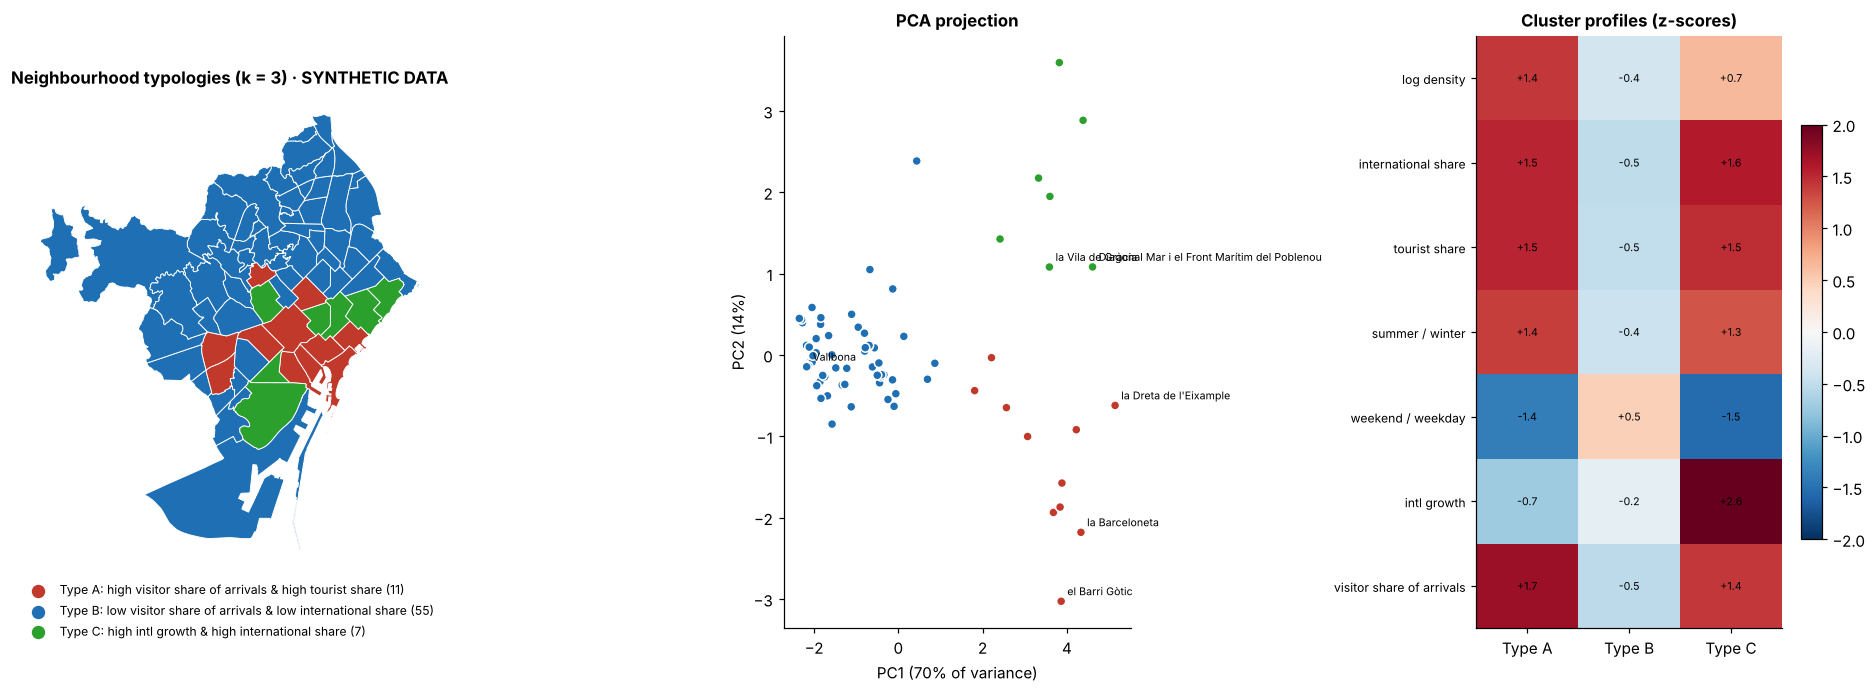

In [21]:
z = (features.drop(columns="cluster") - features.drop(columns="cluster").mean()) / features.drop(columns="cluster").std()
profile = z.groupby(features["cluster"]).mean()
def describe(row):
    top = row.abs().sort_values(ascending=False).index[:2]
    return " & ".join(("high " if row[t] > 0 else "low ") + t for t in top)
names = {c: f"Type {chr(65 + i)}: {describe(profile.loc[c])}" for i, c in enumerate(profile.index)}
CL_COLORS = dict(zip(profile.index, ["#c0392b", "#1f6fb4", "#2ca02c", "#f08a24", "#8e44ad", "#7f8c8d"]))

fig = plt.figure(figsize=(17, 6.5)); gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1, 1.1])
ax = fig.add_subplot(gs[0])
cv.plot_map(geo, ax=ax, categories={c: CL_COLORS[k] for c, k in features["cluster"].items()}, title=f"Neighbourhood typologies (k = {cl['k']}){TAG}")
for k, n in names.items():
    ax.scatter([], [], color=CL_COLORS[k], s=60, label=f"{n} ({(features['cluster'] == k).sum()})")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, 0), fontsize=8)
ax = fig.add_subplot(gs[1])
ax.scatter(cl["pca"][:, 0], cl["pca"][:, 1], c=[CL_COLORS[k] for k in cl["labels"]], s=35, edgecolor="white")
for i, c in enumerate(CODES):
    if c in ("80190102", "80190207", "80191069", "80190631", "80190856", "80190103"):
        ax.annotate(NAME[c], cl["pca"][i], fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel(f"PC1 ({cl['explained'][0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({cl['explained'][1]:.0%})"); ax.set_title("PCA projection")
ax = fig.add_subplot(gs[2])
im = ax.imshow(profile.T.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_yticks(range(profile.shape[1]), profile.columns, fontsize=8); ax.set_xticks(range(len(profile)), [names[c].split(":")[0] for c in profile.index])
for (i, j), v in np.ndenumerate(profile.T.to_numpy()):
    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7)
ax.set_title("Cluster profiles (z-scores)"); fig.colorbar(im, ax=ax, shrink=.7)
fig.tight_layout(); save(fig, "typologies"); plt.show()

**Reading.** The cluster names are generated automatically from each group's two most distinctive indicators, so they stay correct when the data change. On the synthetic data three types appear: a **consolidated visitor core** (dense, international, touristic and seasonal), **emerging areas** where international visitors grow fastest (the planted "diffusion"), and **mainly residential neighbourhoods**, where regional visitors and weekend peaks dominate. PC1 alone explains about 70% of the variance and is essentially "visitor intensity", while PC2 separates the emerging areas from the consolidated core.

## 7. Visitors vs residents: how they move (M1, RQ-04, RQ-05)
M1 counts **trips** between neighbourhoods. Residents appear only in the mobility files, which makes this the dataset where both groups can be compared directly. The synthetic sample covers one winter week and one summer week of 2025.
### 7.1 Distance decay: a gravity model
For each segment we fit a **Poisson gravity model with origin and destination fixed effects**:
$\log E[T_{ij}] = a_i + b_j - \beta\, d_{ij}$.
The fixed effects absorb how much each neighbourhood generates and attracts, so $\beta$ isolates **how quickly trips fade with distance**. A higher $\beta$ means more local movement. Poisson keeps the zero flows, which a log-linear regression would have to drop.

In [22]:
cent = geom.set_index("cod_barrio")
D = pd.DataFrame(an.distance_matrix(LONLAT), index=CODES, columns=CODES)
dist = lambda df: D.to_numpy()[D.index.get_indexer(df["barrio_origen"]), D.columns.get_indexer(df["barrio_destino"])]
summer = m1[m1["day"] >= "2025-08-01"]
res = []
for o in ["Residente", "Regional", "Nacional", "Internacional"]:
    daily_od = summer[summer["origen"] == o]
    od = daily_od.groupby(["barrio_origen", "barrio_destino"])["viajes"].sum().reset_index()
    naive = an.gravity_model(od, dist(od))                  # published zeros taken at face value
    cens = an.censored_gravity(daily_od, dist(daily_od))    # published zeros = "fewer than 15 trips"
    res.append({"segment": o, "β naive (zeros = 0)": naive["beta"], "β censoring-aware": cens["beta"],
                "planted β": truth["gravity_beta_per_km"][o] if SYNTHETIC else np.nan,
                "half-distance (km)": np.log(2) / cens["beta"],
                "mean trip length (km)": np.average(dist(od), weights=od["viajes"]), "naive pseudo R²": naive["pseudo_r2"]})
gravity = pd.DataFrame(res).set_index("segment")
gravity.style.format("{:.3f}", subset=["β naive (zeros = 0)", "β censoring-aware", "planted β"]).format(
    "{:.2f}", subset=["half-distance (km)", "mean trip length (km)", "naive pseudo R²"])

,β naive (zeros = 0),β censoring-aware,planted β,half-distance (km),mean trip length (km),naive pseudo R²
segment,,,,,,
Residente,0.358,0.299,0.300,2.32,3.09,0.95
Regional,0.501,0.451,0.450,1.54,2.07,0.99
Nacional,0.613,0.549,0.550,1.26,1.96,0.99
Internacional,0.710,0.651,0.650,1.06,1.89,0.99


**What this shows.**
1. All four segments have a clear distance decay. On the synthetic data, visitors (especially international ones) move more locally than residents, which is the kind of contrast the challenge asks about (RQ-04).
2. **The privacy rule biases the naive estimate.** Daily flows below 15 trips are published as 0, so thin long-distance flows look like *no* flows and the decay is overstated. The censoring-aware model treats each published 0 as "between 0 and 14 trips" (a censored Poisson likelihood with origin, destination and day fixed effects, fitted by maximum likelihood) and **recovers the planted values**. This is the method we will use on the real data.
3. *Half-distance* is the distance at which the expected number of trips halves, all else being equal. The mean trip length also depends on where each group is concentrated, while β does not, which is why we use the model and not just averages.

### 7.2 Which neighbourhoods are hubs for each group? (PageRank)

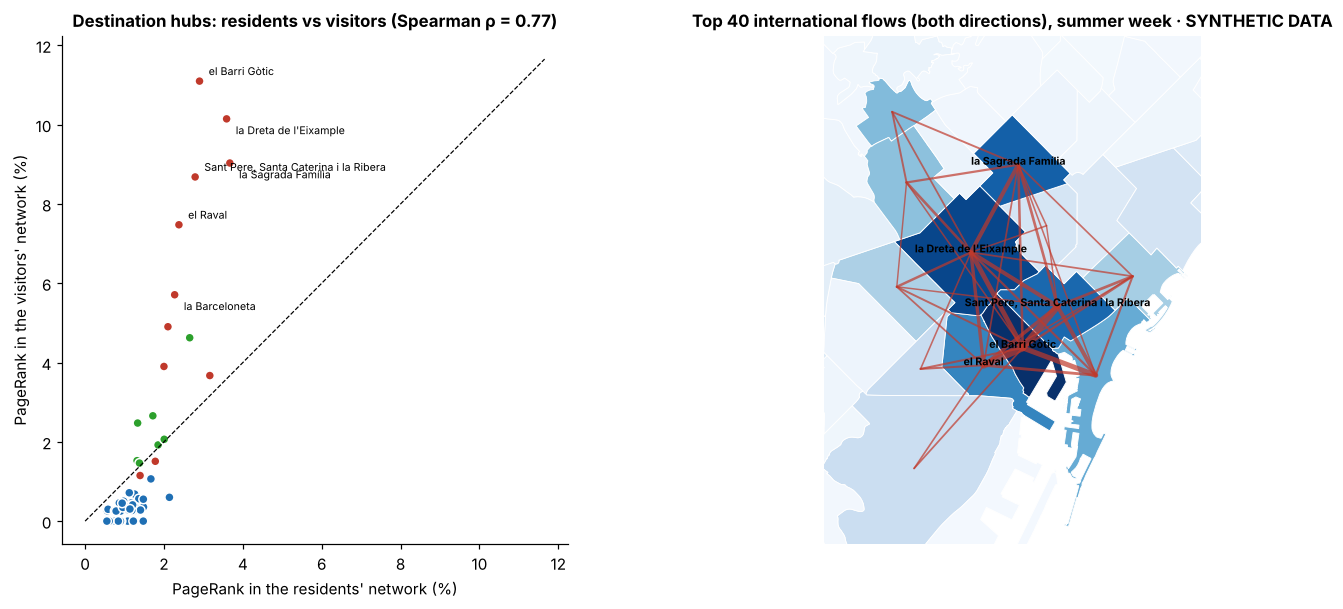

In [23]:
from scipy.stats import spearmanr
pr_res = an.pagerank(summer[summer["origen"] == "Residente"])
pr_vis = an.pagerank(summer[summer["origen"].isin(VISITORS)].groupby(["barrio_origen", "barrio_destino"], as_index=False)["viajes"].sum())
pr = pd.DataFrame({"residents": pr_res, "visitors": pr_vis}).reindex(CODES).fillna(0)
rho = spearmanr(pr["residents"], pr["visitors"])[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
ax.scatter(pr["residents"] * 100, pr["visitors"] * 100, c=[CL_COLORS[k] for k in features["cluster"].reindex(CODES)], s=35, edgecolor="white")
lim = max(pr.max()) * 105; ax.plot([0, lim], [0, lim], "k--", lw=.8)
for i, c in enumerate(pr.assign(gap=pr["visitors"] - pr["residents"]).abs().nlargest(6, "gap").index):
    ax.annotate(NAME[c], (pr.loc[c, "residents"] * 100, pr.loc[c, "visitors"] * 100), fontsize=7,
                xytext=(6, -10 if i % 2 else 4), textcoords="offset points")
ax.set_xlabel("PageRank in the residents' network (%)"); ax.set_ylabel("PageRank in the visitors' network (%)")
ax.set_title(f"Destination hubs: residents vs visitors (Spearman ρ = {rho:.2f})")

ax = axes[1]
und = summer[summer["origen"] == "Internacional"].assign(
    a=lambda d: np.minimum(d["barrio_origen"], d["barrio_destino"]), b=lambda d: np.maximum(d["barrio_origen"], d["barrio_destino"]))
flows = und.groupby(["a", "b"])["viajes"].sum().nlargest(40)
cv.plot_map(geo, values=pr["visitors"].to_dict(), ax=ax, cmap="Blues", colorbar=False,
            title=f"Top 40 international flows (both directions), summer week{TAG}")
for (a, b), v in flows.items():
    ax.plot(cent.loc[[a, b], "lon"], cent.loc[[a, b], "lat"], color="#c0392b", lw=.5 + 4 * v / flows.max(), alpha=.7, solid_capstyle="round")
inv = cent.loc[list({c for ab in flows.index for c in ab})]
ax.set_xlim(inv["lon"].min() - .012, inv["lon"].max() + .012); ax.set_ylim(inv["lat"].min() - .01, inv["lat"].max() + .01)
for c in pr["visitors"].nlargest(5).index:
    ax.annotate(NAME[c], cent.loc[c, ["lon", "lat"]].to_numpy(float), fontsize=7, ha="center", fontweight="bold")
save(fig, "networks"); plt.show()

### 7.3 Visitor share of arrivals: winter vs summer
Out of all trips arriving in a neighbourhood, what fraction is made by visitors? This is the most direct measure of **"sharing the same space"** that the data allow, and comparing a winter week with a summer week shows the seasonal shift.

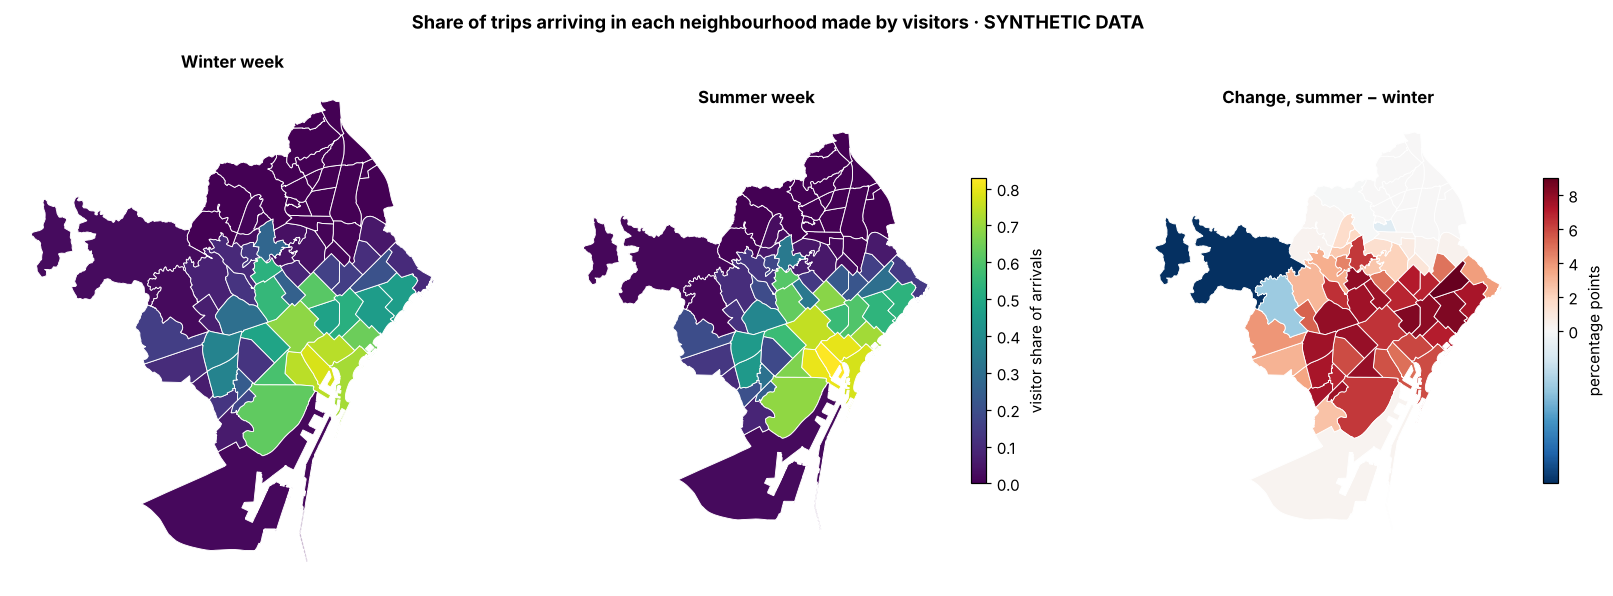

In [24]:
def visitor_share(df):
    a = df.groupby(["barrio_destino", "origen"])["viajes"].sum().unstack()
    return a[VISITORS].sum(axis=1) / a.sum(axis=1)
share_w, share_s = visitor_share(m1[m1["day"] < "2025-03-01"]), visitor_share(summer)
norm = colors.Normalize(0, max(share_w.max(), share_s.max()))
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
cv.plot_map(geo, values=share_w.to_dict(), ax=axes[0], norm=norm, cmap="viridis", colorbar=False, title="Winter week")
cv.plot_map(geo, values=share_s.to_dict(), ax=axes[1], norm=norm, cmap="viridis", legend_label="visitor share of arrivals", title="Summer week")
chg = (share_s - share_w) * 100
cv.plot_map(geo, values=chg.to_dict(), ax=axes[2], cmap="RdBu_r", legend_label="percentage points",
            norm=colors.TwoSlopeNorm(vcenter=0, vmin=min(-1, chg.min()), vmax=max(1, chg.max())), title="Change, summer − winter")
fig.suptitle(f"Share of trips arriving in each neighbourhood made by visitors{TAG}", fontweight="bold")
save(fig, "visitor_share_arrivals"); plt.show()

## 8. Coexistence Pressure Index
We summarise "pressure on coexistence" with four indicators, each linked to a different aspect of the challenge question:

| Indicator | Captures | Source |
|---|---|---|
| Visitor density (log, per km²) | How crowded with visitors | T4 + map |
| Visitor share of arrivals (summer) | How much the space is shared with residents | M1 |
| Summer / winter ratio | How abrupt the seasonal change is | T4 |
| International growth | Whether pressure is rising | T4 |

Each is min-max normalised and averaged (0 = lowest, 100 = highest). A composite index is only useful if it does not depend heavily on arbitrary weights, so we **recompute it with 500 random weightings** and measure how stable the ranking is.

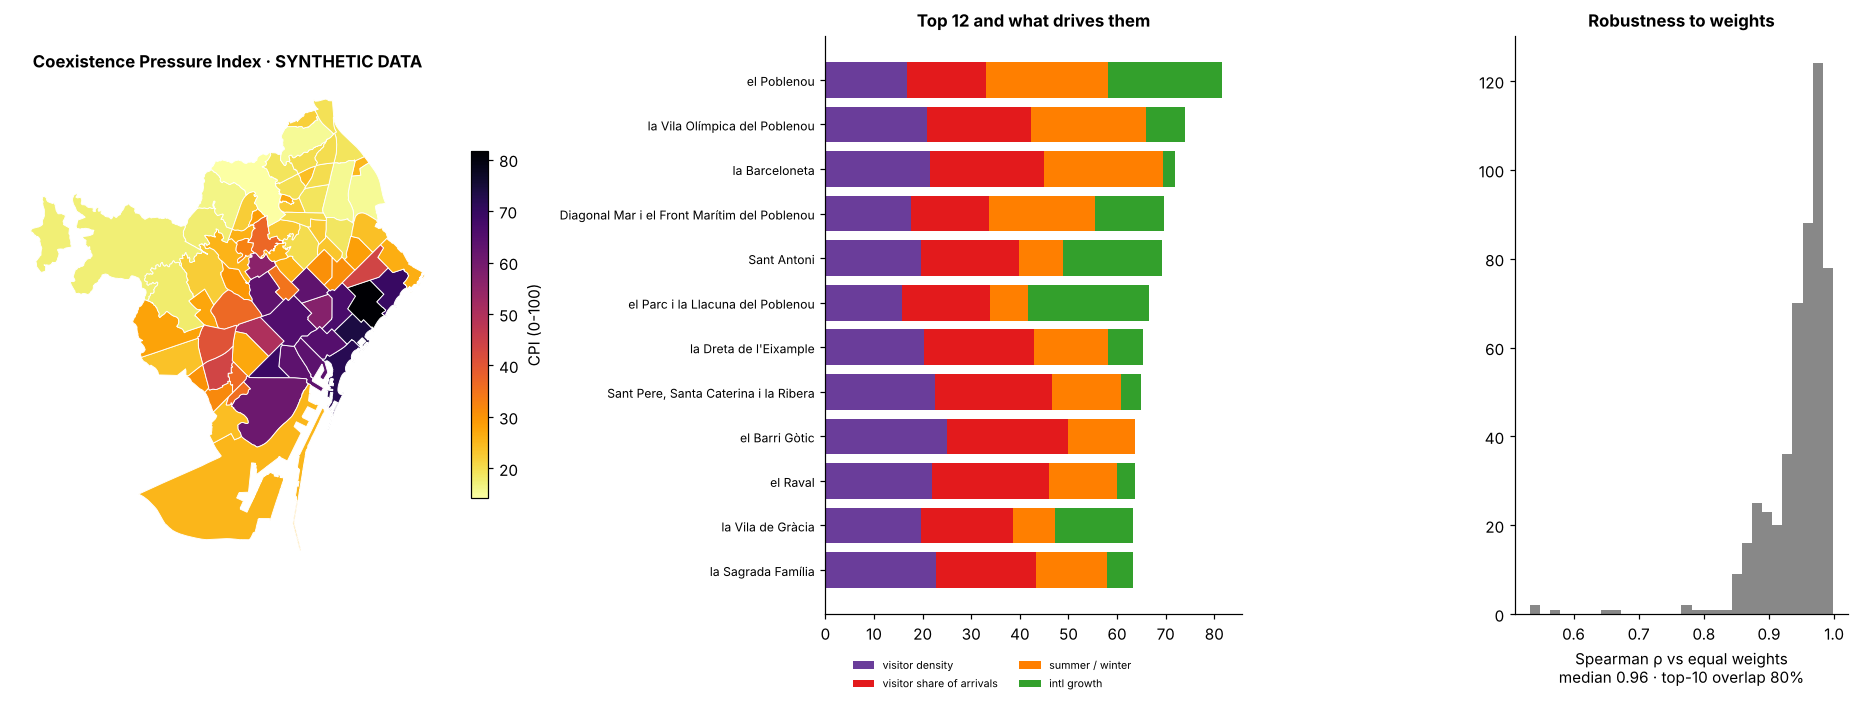

Interactive map: outputs/coexistence_index_interactive.html


In [25]:
ind = pd.DataFrame({"visitor density": features["log density"], "visitor share of arrivals": share_s.reindex(CODES).fillna(0),
                    "summer / winter": features["summer / winter"], "intl growth": features["intl growth"]})
cpi = an.composite_index(ind).rename("CPI")
rhos, overlap = an.weight_sensitivity(ind)

fig = plt.figure(figsize=(17, 6.5)); gs = fig.add_gridspec(1, 3, width_ratios=[1.3, 1, .8])
ax = fig.add_subplot(gs[0]); cv.plot_map(geo, values=cpi.to_dict(), ax=ax, cmap="inferno_r", legend_label="CPI (0-100)",
                                         title=f"Coexistence Pressure Index{TAG}")
ax = fig.add_subplot(gs[1]); top = cpi.nlargest(12)[::-1]
norm_ind = ind.apply(an.minmax).loc[top.index] / ind.shape[1] * 100
left = np.zeros(len(top))
for col, c in zip(norm_ind.columns, ["#6a3d9a", "#e31a1c", "#ff7f00", "#33a02c"]):
    ax.barh([NAME[k] for k in top.index], norm_ind[col], left=left, color=c, label=col); left += norm_ind[col].to_numpy()
ax.legend(frameon=False, fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(.4, -.06)); ax.set_title("Top 12 and what drives them"); ax.tick_params(axis="y", labelsize=8)
ax = fig.add_subplot(gs[2]); ax.hist(rhos, bins=30, color="#888"); ax.set_title("Robustness to weights")
ax.set_xlabel(f"Spearman ρ vs equal weights\nmedian {np.median(rhos):.2f} · top-10 overlap {np.median(overlap):.0%}")
fig.tight_layout(); save(fig, "coexistence_index"); plt.show()
cv.interactive_map(geo, cpi.reset_index().rename(columns={"index": "cod_barrio"}), value_col="CPI", path=cv.OUT_DIR / "coexistence_index_interactive.html")
print("Interactive map: outputs/coexistence_index_interactive.html")

## 9. Who: origin markets and length of stay (T8, T3)

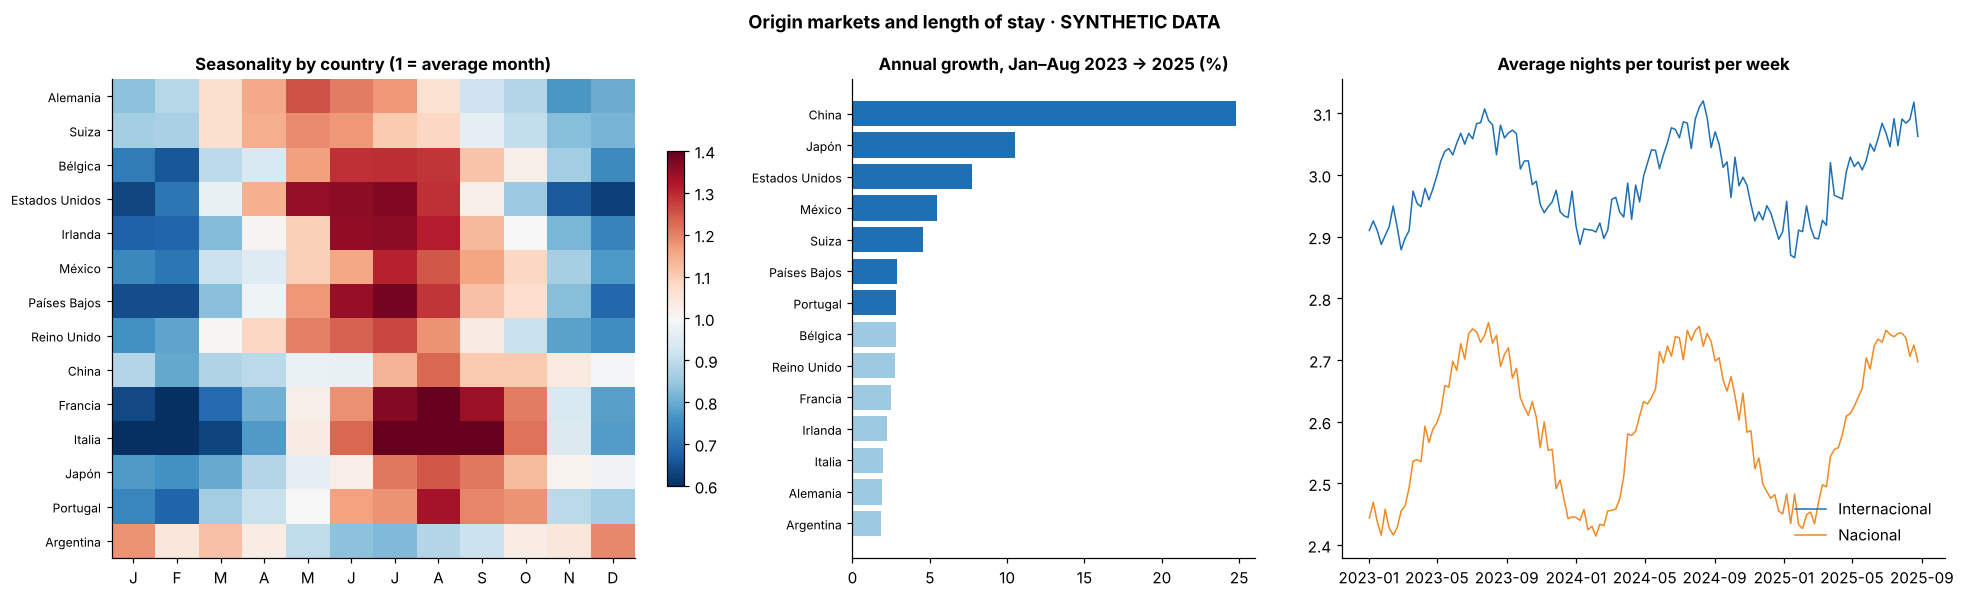

In [26]:
t8 = data["T8"]
c = t8.groupby(["pais_Residencia", "mes"])["visitantes"].sum().unstack().drop(index="Resto del mundo")
season = c.T.groupby(c.columns.str[4:]).mean().T
season = season.div(season.mean(axis=1), axis=0)
order = season.idxmax(axis=1).sort_values().index
ytd = lambda y: c[[m for m in c.columns if m.startswith(y) and m[4:] <= "08"]].sum(axis=1)
cagr = ((ytd("2025") / ytd("2023")) ** 0.5 - 1).sort_values()

t3 = data["T3"].dropna(subset=["visitantes"])
t3 = t3.assign(start=pd.to_datetime(t3["periodo"].str[:10]))
nights = t3.groupby(["start", "origen"]).apply(lambda g: np.average(g["pernoctaciones"], weights=g["visitantes"])).unstack()

fig = plt.figure(figsize=(18, 5.5)); gs = fig.add_gridspec(1, 3, width_ratios=[1.3, .8, 1.2])
ax = fig.add_subplot(gs[0]); im = ax.imshow(season.loc[order].to_numpy(), cmap="RdBu_r", vmin=.6, vmax=1.4, aspect="auto")
ax.set_yticks(range(len(order)), order, fontsize=8); ax.set_xticks(range(12), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_title("Seasonality by country (1 = average month)"); fig.colorbar(im, ax=ax, shrink=.7)
ax = fig.add_subplot(gs[1]); ax.barh(cagr.index, cagr * 100, color=np.where(cagr > cagr.median(), "#1f6fb4", "#9ecae1"))
ax.set_title("Annual growth, Jan–Aug 2023 → 2025 (%)"); ax.tick_params(axis="y", labelsize=8)
ax = fig.add_subplot(gs[2])
for o in nights.columns:
    ax.plot(nights.index, nights[o], color=COLORS[o], label=o, lw=1)
ax.set_title("Average nights per tourist per week"); ax.legend(frameon=False)
fig.suptitle(f"Origin markets and length of stay{TAG}", fontweight="bold"); fig.tight_layout()
save(fig, "markets_stays"); plt.show()

## 10. Traceability, limitations and next steps
### 10.1 Requirements coverage (PWP §2.1)
| RQ | Requirement | Where | Status after Iteration 1 |
|---|---|---|---|
| RQ-01 | Jan 2023 to Aug 2025, equivalent periods | §2.1 coverage, §4.4 same-weekday YoY, §5.5 Jan–Aug comparison | Method ready |
| RQ-02 | Barcelona neighbourhoods, linked by code | §3 map, §2.1 code check | Done |
| RQ-03 | Regional / national / international segments | Throughout (colour code) | Method ready |
| RQ-04 | Compare with residents, no causal claims | §7 gravity, PageRank, visitor share | Method ready |
| RQ-05 | Unique visitors and trips kept separate | §1.1 rules; §5 uses T4, §7 uses M1 | Done |
| RQ-06 | Overnight stays at municipality level only | §9 (T3) | Method ready |
| RQ-07 | Data quality checks documented | §2, `data_review_plan.md` | Done (validated on planted problems) |
| RQ-08 | Privacy threshold explained | §1.1 rules, §2.4 NA handling | Done |
| RQ-09 | Neighbourhood maps | §3, §5, §6, §7.3, §8 | Method ready |
| RQ-10 | Day of week, month, year | §4.1–4.4 | Method ready |
| RQ-11 | Filters by period and origin | All functions take period and origin as parameters; dashboard in Iteration 2 | Partial |
| RQ-12 | Aggregated tables | Every result is an aggregated table, exportable | Partial |
| RQ-13 | Reproducible notebook | One `Run All`, fixed seeds, `requirements.txt` | Done (to be tested on another computer) |
| RQ-15 | ≥ 3 findings with chart and limit | Candidate analyses in §4–§9 | Waiting for real data |
| RQ-18 | Data protection | `data/raw/` is git-ignored; only aggregates are shown | Done |

### 10.2 What the synthetic run shows, and what it does not
- **It shows** that the pipeline runs end to end, that the data review catches all the planted problems, that the event detector finds all 17 planted events in the right places, and that the censoring-aware gravity model recovers the planted distance decay where the naive one does not.
- **It does not show** anything about Barcelona. Any pattern in the maps and charts (hot spots, growth, typologies, index ranking) comes from the synthetic model.
- **Method limits to keep in mind with the real data:** with only 32 months the yearly cycle is estimated from fewer than 3 cycles (hence the smooth Fourier model in §4.2); events lasting several weeks are partly absorbed by the trend; densities use the total area, including parks and the port; M1 shows trips between neighbourhoods only, not trips inside them; the index depends on the choice of indicators, though its weights matter little (§8).

### 10.3 Next steps (Iteration 2, 27 Oct to 9 Nov)
1. Load the real files in `data/raw/`, run §2, and agree with the mentor on file names, separators, code formats and how NA is published.
2. Replace the synthetic results with real ones and select the **3 main findings** (RQ-15), each with its chart and its limit.
3. Turn the episodes found by §4.3 into a calendar of named events, and ask the mentor about any that cannot be explained.
4. Start the dashboard (RQ-09 to RQ-11): maps and charts from §4, §5 and §8 with filters by period and origin.

In [27]:
print("Figures written to outputs/:")
for p in sorted(cv.OUT_DIR.glob("*")):
    print(" ", p.name)

Figures written to outputs/:
  base_map.png
  base_map_interactive.html
  coexistence_index.png
  coexistence_index_interactive.html
  concentration.png
  coverage_calendar.png
  decomposition.png
  density_maps.png
  dispersion_growth.png
  location_quotients.png
  markets_stays.png
  monthly_visitors.png
  morans_lisa.png
  networks.png
  typologies.png
  visitor_share_arrivals.png
  yoy_same_weekday.png
